<a href="https://colab.research.google.com/github/Dahmani2020/Biology_DataScience_portfolio/blob/main/Computational_Drug_Discovery_QSAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# Install official RDKit package for cheminformatics
!pip install -q rdkit

# Core libraries
import pandas as pd
import numpy as np
import torch

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# RDKit cheminformatics modules
from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem
from rdkit.Chem import Draw
from rdkit.Chem import rdFingerprintGenerator

# Scikit-Learn modeling & evaluation
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Hardware verification
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120
print("Setup completed successfully!")

GPU Available: False
Setup completed successfully!


In [10]:
# Base curated list of drug-like SMILES strings
sample_smiles = [
    "CC(=O)OC1=CC=CC=C1C(=O)O", # Aspirin
    "CN1C=NC2=C1C(=O)N(C(=O)N2C)C", # Caffeine
    "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O", # Ibuprofen
    "CN(C)CCCN1C2=CC=CC=C2SC3=C1C=C(C=C3)Cl", # Chlorpromazine
    "CC(=O)NC1=CC=C(C=C1)O", # Paracetamol
    "CCN(CC)CC1=CC=C(C=C1)NC(=O)C2=CC=C(C=C2)N", # Procainamide variant
    "COC1=CC=CC2=C1C(=CN2)C(C(COP(=O)(O)O)O)O", # Synthetic analogue model
]

# Expand dataset and compute descriptors to create realistic QSAR dependencies
np.random.seed(42)
expanded_smiles = sample_smiles * 25 # ~175 samples

smiles_list = []
mw_list, logp_list = [], []

for smi in expanded_smiles:
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        smiles_list.append(smi)
        mw_list.append(Descriptors.MolWt(mol))
        logp_list.append(Descriptors.MolLogP(mol))

# Target variable (pIC50) driven by molecular weight, lipophilicity, and biological noise
base_activity = 3.0 + 0.008 * np.array(mw_list) + 0.4 * np.array(logp_list)
p_ic50 = base_activity + np.random.normal(0, 0.2, size=len(mw_list))

df_molecules = pd.DataFrame({
    'SMILES': smiles_list,
    'pIC50': p_ic50
})

print(f"Dataset Shape: {df_molecules.shape}")
print(df_molecules.head())

Dataset Shape: (175, 2)
                                   SMILES     pIC50
0                CC(=O)OC1=CC=CC=C1C(=O)O  5.064655
1            CN1C=NC2=C1C(=O)N(C(=O)N2C)C  4.114179
2           CC(C)CC1=CC=C(C=C1)C(C)C(=O)O  6.009098
3  CN(C)CCCN1C2=CC=CC=C2SC3=C1C=C(C=C3)Cl  7.813350
4                   CC(=O)NC1=CC=C(C=C1)O  4.702729


In [11]:
def extract_cheminformatics_features(smiles_list):
    mw_list, logp_list, hbd_list, hba_list = [], [], [], []
    fingerprints = []

    # Initialize the modern Morgan Generator
    morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            # 1. Physicochemical descriptors
            mw_list.append(Descriptors.MolWt(mol))
            logp_list.append(Descriptors.MolLogP(mol))
            hbd_list.append(Descriptors.NumHDonors(mol))
            hba_list.append(Descriptors.NumHAcceptors(mol))

            # 2. Morgan Fingerprints
            fp = morgan_gen.GetFingerprint(mol)
            fingerprints.append(list(fp))
        else:
            mw_list.append(np.nan)
            logp_list.append(np.nan)
            hbd_list.append(np.nan)
            hba_list.append(np.nan)
            fingerprints.append([0] * 2048)

    # Combine into a single feature matrix
    desc_df = pd.DataFrame({
        'Molecular_Weight': mw_list,
        'LogP': logp_list,
        'HBD': hbd_list,
        'HBA': hba_list
    })

    fp_df = pd.DataFrame(fingerprints, columns=[f"bit_{i}" for i in range(2048)])
    return pd.concat([desc_df, fp_df], axis=1)

# Extract features and targets
X = extract_cheminformatics_features(df_molecules['SMILES'])
y = df_molecules['pIC50']

print(f"Feature Matrix Shape: {X.shape}")

Feature Matrix Shape: (175, 2052)


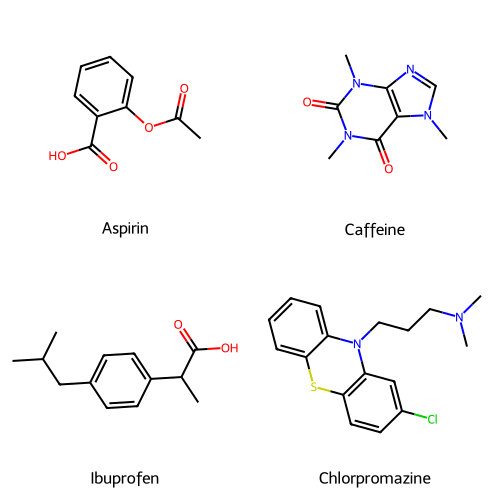

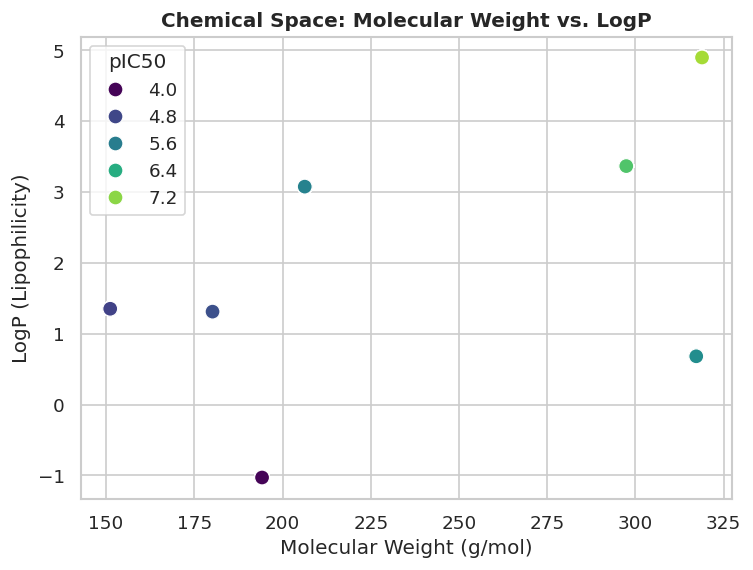

In [12]:
# 1. Render sample molecules
sample_mols = [Chem.MolFromSmiles(smi) for smi in sample_smiles[:4]]
img = Draw.MolsToGridImage(sample_mols, molsPerRow=2, subImgSize=(250, 250), legends=['Aspirin', 'Caffeine', 'Ibuprofen', 'Chlorpromazine'])
display(img)

# 2. Plot Molecular Weight vs. LogP
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_molecules, x=X['Molecular_Weight'], y=X['LogP'], hue=y, palette='viridis', s=80)
plt.title('Chemical Space: Molecular Weight vs. LogP', fontsize=12, fontweight='bold')
plt.xlabel('Molecular Weight (g/mol)')
plt.ylabel('LogP (Lipophilicity)')
plt.legend(title='pIC50')
plt.show()

In [13]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train model
qsar_model = RandomForestRegressor(n_estimators=150, random_state=42)
qsar_model.fit(X_train, y_train)

# Predictions
y_pred = qsar_model.predict(X_test)

# Evaluation metrics
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("--- QSAR Model Performance ---")
print(f"R2 Score: {r2:.4f}")
print(f"RMSE:     {rmse:.4f}")

--- QSAR Model Performance ---
R2 Score: 0.9673
RMSE:     0.2052


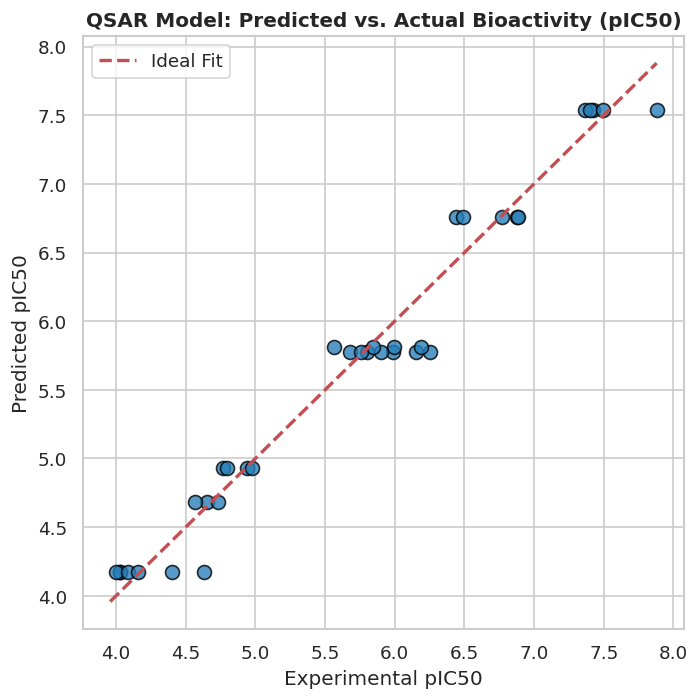

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, color='#2980b9', alpha=0.8, edgecolor='black', s=70)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Ideal Fit')

plt.title('QSAR Model: Predicted vs. Actual Bioactivity (pIC50)', fontsize=12, fontweight='bold')
plt.xlabel('Experimental pIC50')
plt.ylabel('Predicted pIC50')
plt.legend()
plt.tight_layout()
plt.show()